# Μ (Mu) | Predicción de Recuperación de Oro mediante Machine Learning

## Contexto empresarial

La industria minera depende de procesos complejos de extracción y refinamiento para maximizar la recuperación de metales valiosos y reducir pérdidas operativas. Pequeñas variaciones en las condiciones de procesamiento pueden afectar significativamente la cantidad de material recuperado, impactando directamente la rentabilidad de la operación.

Zyfra desarrolla soluciones tecnológicas orientadas a la optimización de procesos industriales en la industria pesada. Como parte de esta estrategia, la compañía busca implementar modelos predictivos capaces de anticipar el desempeño de las distintas etapas del proceso de recuperación de oro.

La capacidad de estimar estos resultados antes de que el proceso concluya permite identificar condiciones de operación más eficientes, optimizar el uso de reactivos, reducir desperdicios y apoyar la toma de decisiones basada en datos.

---

## Problema de negocio

El proceso de extracción de oro se compone de múltiples etapas de flotación y purificación. Durante cada una de ellas se registran decenas de variables relacionadas con la alimentación del mineral, concentraciones metálicas, niveles de reactivos, condiciones físicas y parámetros operativos.

Actualmente, la empresa necesita construir un sistema capaz de predecir dos indicadores críticos del proceso:

- Recuperación del concentrado rougher (`rougher.output.recovery`).
- Recuperación del concentrado final (`final.output.recovery`).

La precisión de estas predicciones permitirá evaluar la eficiencia de producción y detectar configuraciones de operación que no generen valor económico para la compañía.

---

## Objetivo general

Desarrollar un modelo de Machine Learning capaz de predecir la recuperación de oro en distintas etapas del proceso industrial utilizando información histórica proveniente de plantas de procesamiento mineral.

---

## Objetivos específicos

- Examinar y validar la calidad de los datos suministrados.
- Verificar la consistencia de los cálculos de recuperación reportados por la compañía.
- Analizar las diferencias existentes entre los conjuntos de entrenamiento y prueba.
- Realizar el preprocesamiento necesario para garantizar datos confiables para el modelado.
- Estudiar el comportamiento de las concentraciones de oro, plata y plomo a lo largo del proceso de refinamiento.
- Detectar posibles anomalías en las etapas de producción.
- Implementar métricas personalizadas de evaluación basadas en sMAPE.
- Entrenar y comparar múltiples modelos predictivos.
- Seleccionar la solución con mejor capacidad de generalización.
- Evaluar el desempeño final sobre datos no observados.

---

## Comprensión del proceso industrial

La recuperación de oro se desarrolla mediante una serie de etapas consecutivas:

### Flotación (Rougher)

El mineral procesado ingresa a instalaciones de flotación donde se utilizan reactivos químicos especializados para separar los metales valiosos del material residual.

Como resultado de esta etapa se obtienen:

- Concentrado rougher.
- Colas rougher.

### Purificación primaria

El concentrado rougher pasa por una primera fase de limpieza orientada a aumentar la concentración de oro y reducir impurezas.

### Purificación secundaria

Posteriormente se realiza una segunda etapa de refinamiento para incrementar aún más la pureza del material recuperado.

### Concentrado final

El producto resultante representa la máxima concentración alcanzada de oro tras completar todas las fases de procesamiento.

---

## Enfoque analítico

Para responder al problema de negocio se seguirá una metodología estructurada en tres fases:

### 1. Preparación de datos

- Exploración inicial de los conjuntos de datos.
- Validación de la fórmula de recuperación.
- Identificación de variables ausentes en el conjunto de prueba.
- Tratamiento de valores faltantes y problemas de calidad.

### 2. Análisis exploratorio

- Evolución de las concentraciones de Au, Ag y Pb.
- Comparación de distribuciones entre entrenamiento y prueba.
- Detección de registros anómalos.
- Evaluación de la calidad de las variables disponibles.

### 3. Modelado predictivo

- Construcción de métricas personalizadas basadas en sMAPE.
- Entrenamiento de diferentes algoritmos.
- Validación cruzada.
- Selección del mejor modelo.
- Evaluación final sobre datos de prueba.

---

## Herramientas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-Learn

---

## Métrica de éxito

El desempeño del modelo será evaluado mediante una versión ponderada del error porcentual absoluto medio simétrico (*sMAPE*), diseñada específicamente para el proceso industrial analizado.

La métrica final considera simultáneamente la calidad de las predicciones sobre:

- Recuperación rougher.
- Recuperación final.

Esto garantiza una evaluación alineada con los objetivos operativos de la compañía y permite seleccionar el modelo con mayor utilidad práctica para la optimización de la producción.

---

## Resultado esperado

Al finalizar el proyecto se obtendrá un modelo capaz de estimar con precisión la recuperación de oro en etapas clave del proceso de refinamiento, proporcionando una herramienta de apoyo para la optimización operativa, la reducción de pérdidas y la mejora continua de la eficiencia productiva.

Primero importamos los datasets fuente, de entrenamiento y de prueba a nuestro entorno de trabajo

In [1]:
import pandas as pd

oro_fuente = pd.read_csv("/content/gold_recovery_full.csv")
oro_entrenamiento = pd.read_csv("/content/gold_recovery_train.csv")
oro_prueba = pd.read_csv("/content/gold_recovery_test.csv")

Ya importados nuestros datasets, analizamos de forma general su estructura, contenido y los tipos de datos que los conforman.

Podemos ver que naturalmente nuestro dataset fuente posee la mayor cantidad de observaciones, en este caso nuestro dataset de entrenamiento contiene la misma cantidad de columnas, presentando una menor cantidad de observaciones, por último el nuestro dataset de prueba presenta la menor de las dimensiones.

La gran mayoria de la estructura del dataset fuente del cual se derivan los datasets de entrenamiento y prueba está conformado por datos de tipo float64 (valores decimales). salvo por la columna "Date" (fecha y hora de adquisición) de tipo object el cual no nos revela información crítica para el modelado.

In [2]:
print("El dataset fuente es el siguiente:")
print(oro_fuente.info())
print(oro_fuente.head(5))
print()
print()
print("El dataset de entrenamiento es el siguiente:")
print(oro_entrenamiento.info())
print(oro_entrenamiento.head(5))
print()
print()
print("El dataset de prueba es el siguiente:")
print(oro_prueba.info())
print(oro_prueba.head(5))

El dataset fuente es el siguiente:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                22716 non-null  object 
 1   final.output.concentrate_ag                         22627 non-null  float64
 2   final.output.concentrate_pb                         22629 non-null  float64
 3   final.output.concentrate_sol                        22331 non-null  float64
 4   final.output.concentrate_au                         22630 non-null  float64
 5   final.output.recovery                               20753 non-null  float64
 6   final.output.tail_ag                                22633 non-null  float64
 7   final.output.tail_pb                                22516 non-null  float64
 8   final.output.tail_sol                    

In [3]:
print("Dimensiones del dataset fuente:")
oro_fuente.shape

Dimensiones del dataset fuente:


(22716, 87)

In [4]:
print("Dimensiones del dataset de entrenamiento:")
oro_entrenamiento.shape

Dimensiones del dataset de entrenamiento:


(16860, 87)

In [5]:
print("Dimensiones del dataset de prueba:")
oro_prueba.shape

Dimensiones del dataset de prueba:


(5856, 53)

Ahora procederemos a descubrir los valores faltantes para nuestros 3 conjuntos de datos.

En este momento podemos ver que un gran número de columnas presentan valores ausentes, por lo que nuestro deber será tratarlos para asegurar un adecuado modelado futuro independientemente del algoritmo que se construya para este fin.

In [6]:
pd.set_option('display.max_rows', None)
oro_fuente.isna().sum()

,0
date,0
final.output.concentrate_ag,89
final.output.concentrate_pb,87
final.output.concentrate_sol,385
final.output.concentrate_au,86
final.output.recovery,1963
final.output.tail_ag,83
final.output.tail_pb,200
final.output.tail_sol,271
final.output.tail_au,81


In [7]:
pd.set_option("display.max_rows", None)
oro_entrenamiento.isna().sum()

,0
date,0
final.output.concentrate_ag,72
final.output.concentrate_pb,72
final.output.concentrate_sol,370
final.output.concentrate_au,71
final.output.recovery,1521
final.output.tail_ag,66
final.output.tail_pb,183
final.output.tail_sol,145
final.output.tail_au,66


In [8]:
pd.set_option("display.max_rows", None)
oro_prueba.isna().sum()

,0
date,0
primary_cleaner.input.sulfate,302
primary_cleaner.input.depressant,284
primary_cleaner.input.feed_size,0
primary_cleaner.input.xanthate,166
primary_cleaner.state.floatbank8_a_air,16
primary_cleaner.state.floatbank8_a_level,16
primary_cleaner.state.floatbank8_b_air,16
primary_cleaner.state.floatbank8_b_level,16
primary_cleaner.state.floatbank8_c_air,16


Para tener una mejor noción de la cantidad de columnas que presentan valores ausentes observaremos algunas métricas descriptoras.

Podemos concluir para el dataste fuente lo siguiente:

1 Se revisaron 87 columnas

2 El porcentaje promedio de valores ausentes es del 1.85%, que podemos determinar como relativamente bajo

3 la desviación estándar alcanza 3.18 puntos porcentuales, lo que indica una dispersión considerable entre las columnas. Esto sugiere que, aunque la mayoría de las variables presentan pocos datos ausentes, algunas concentran una proporción significativamente mayor de valores faltantes.

4 Existen columnas que no presentan valores ausentes ya que se reporta un porcentaje del 0.00%

5 la columna rougher.output.recovery presenta el porcentaje  más alto de valores ausentes (13.73%)

In [9]:
faltantes_fuente = (oro_fuente.isna().sum()) / len(oro_fuente) * 100
faltantes_fuente.describe()

,0
count,87.000000
mean,1.851295
std,3.183459
min,0.000000
25%,0.327963
50%,0.444621
75%,1.562775
max,13.730410


Podemos concluir para el dataste de entrenamiento lo siguiente:

1 Se revisaron 87 columnas.

2 El porcentaje promedio de valores ausentes es del 2.06%, que podemos determinar como bajo.

3 la desviación estándar alcanza 3.54 puntos porcentuales, lo que indica una dispersión considerable entre las columnas. Esto sugiere que, aunque la mayoría de las variables presentan pocos datos ausentes, algunas concentran una proporción significativamente mayor de valores faltantes.

4 Existen columnas que no presentan valores ausentes ya que se reporta un porcentaje del 0.00%.

5 la columna rougher.output.recovery nuevamente y de forma espereada presenta el porcentaje más alto de valores ausentes (15.26%).

In [10]:
faltantes_fuente.idxmax()

'rougher.output.recovery'

In [11]:
faltantes_entrenamiento = (oro_entrenamiento.isna().sum()) / len(oro_entrenamiento) * 100
faltantes_entrenamiento.describe()

,0
count,87.000000
mean,2.067057
std,3.548395
min,0.000000
25%,0.344009
50%,0.504152
75%,1.699288
max,15.260973


In [12]:
faltantes_entrenamiento.idxmax()

'rougher.output.recovery'

Podemos concluir para el dataste de entrenamiento lo siguiente:

1 Se revisaron 87 columnas.

2 El porcentaje promedio de valores ausentes es del 0.76%, que podemos determinar como el más bajo.

3 la desviación estándar alcanza 1.34 puntos porcentuales, lo que indica una dispersión moderada entre las columnas. Esto sugiere que, aunque la mayoría de las variables presentan pocos datos ausentes, algunas concentran una proporción levemente mayor de valores faltantes.

4 Existen columnas que no presentan valores ausentes ya que se reporta un porcentaje del 0.00%.

5 la columna rougher.input.floatbank11_xanthate presenta el porcentaje más alto de valores ausentes (6.02%).

In [13]:
faltantes_prueba = (oro_prueba.isna().sum()) / len(oro_prueba) * 100
faltantes_prueba.describe()

,0
count,53.000000
mean,0.760388
std,1.343197
min,0.000000
25%,0.273224
50%,0.273224
75%,0.290301
max,6.028005


In [14]:
faltantes_prueba.idxmax()

'rougher.input.floatbank11_xanthate'

Ahora procederemos a comprobar que el cálculo de recuperación de oro sea correcto comparando el valor de la característica rougher.output.recovery del conjunto de entrenamiento con nuestro propio resultado, luego usaremos la métrica EAM para evaluar la calidad del resultado.

In [15]:
columnas_recuperacion = ["rougher.output.concentrate_au", "rougher.input.feed_au", "rougher.output.tail_au", "rougher.output.recovery"]

columnas_recuperacion_entrenamiento = oro_entrenamiento[columnas_recuperacion]

columnas_recuperacion_entrenamiento.head()

,rougher.output.concentrate_au,rougher.input.feed_au,rougher.output.tail_au,rougher.output.recovery
0,19.793808,6.486150,1.170244,87.107763
1,20.050975,6.478583,1.184827,86.843261
2,19.737170,6.362222,1.162562,86.842308
3,19.320810,6.118189,1.079755,87.226430
4,19.216101,5.663707,1.012642,86.688794


In [16]:
numerador = columnas_recuperacion_entrenamiento["rougher.output.concentrate_au"] * (columnas_recuperacion_entrenamiento["rougher.input.feed_au"] - columnas_recuperacion_entrenamiento["rougher.output.tail_au"])
denominador = columnas_recuperacion_entrenamiento["rougher.input.feed_au"] * (columnas_recuperacion_entrenamiento["rougher.output.concentrate_au"] - columnas_recuperacion_entrenamiento["rougher.output.tail_au"])

division = numerador / denominador

recuperacion = division * 100

print(recuperacion)


0        8.710776e+01
1        8.684326e+01
2        8.684231e+01
3        8.722643e+01
4        8.668879e+01
5        8.815691e+01
6        8.816807e+01
7        8.766834e+01
8        8.703586e+01
9        8.765087e+01
10       8.828070e+01
11       8.849912e+01
12       8.929998e+01
13       8.951970e+01
14       8.723544e+01
15       8.513629e+01
16       8.544350e+01
17       8.648983e+01
18       8.546223e+01
19       8.624179e+01
20       8.658258e+01
21       8.682412e+01
22       8.813224e+01
23       8.591050e+01
24       8.626238e+01
25       8.756110e+01
26       8.758085e+01
27       8.710769e+01
28       8.743171e+01
29       8.679821e+01
30       8.806690e+01
31       8.880472e+01
32       8.996441e+01
33       8.630399e+01
34       8.729828e+01
35       8.544805e+01
36       8.732384e+01
37       8.815122e+01
38       8.801296e+01
39       8.563384e+01
40       8.501783e+01
41       8.794148e+01
42       8.620560e+01
43       8.207843e+01
44       9.140858e+01
45      -0

Dado que la fórmula matemática de recuperación de oro no funciona con valores ausentes:

Recovery=F(C−T)C(F−T)​×100

procederemos a eliminar las filas que contienen dichas vacantes de información.

In [17]:
columnas_recuperacion_entrenamiento_limpias = columnas_recuperacion_entrenamiento.dropna()
columnas_recuperacion_entrenamiento_limpias.shape

(14287, 4)

Ahora debemos recalcular la recuperación, pero usando el DataFrame limpio.

In [18]:
numerador = columnas_recuperacion_entrenamiento_limpias["rougher.output.concentrate_au"] * (columnas_recuperacion_entrenamiento_limpias["rougher.input.feed_au"] - columnas_recuperacion_entrenamiento_limpias["rougher.output.tail_au"])
denominador = columnas_recuperacion_entrenamiento_limpias["rougher.input.feed_au"] * (columnas_recuperacion_entrenamiento_limpias["rougher.output.concentrate_au"] - columnas_recuperacion_entrenamiento_limpias["rougher.output.tail_au"])

division = numerador / denominador

recuperacion_calculada = division * 100

print(recuperacion_calculada.isna().sum())

0


In [19]:
recuperacion_real = columnas_recuperacion_entrenamiento_limpias["rougher.output.recovery"]
len(recuperacion_real)

14287

In [20]:
len(recuperacion_calculada)

14287

In [21]:
from sklearn.metrics import mean_absolute_error
EAM = mean_absolute_error(recuperacion_real, recuperacion_calculada)
print("El error medio absoluto es de: ", EAM)

El error medio absoluto es de:  9.303415616264301e-15


Con este resultado nos dimos cuente que el error medio absoluto es de 0.0000000000000093, el cual es un resultado extremadamente pequeño.

Esto nos indica que los valores originales de la columna rougher.output.recovery concuerdan casi en su totalidad con los calculos que nos arroja la fórmula Recovery=F(C−T)C(F−T)​×100

A continuación, se compararán las columnas de los conjuntos de entrenamiento y prueba para identificar las características que no están disponibles en la muestra de prueba y analizar el tipo de parámetros y tipos al que pertenecen.

In [22]:
columnas_faltantes = (set(oro_entrenamiento.columns) - set(oro_prueba.columns))
columnas_faltantes_ordenadas = sorted(columnas_faltantes)
print(columnas_faltantes_ordenadas)
len(columnas_faltantes_ordenadas)

['final.output.concentrate_ag', 'final.output.concentrate_au', 'final.output.concentrate_pb', 'final.output.concentrate_sol', 'final.output.recovery', 'final.output.tail_ag', 'final.output.tail_au', 'final.output.tail_pb', 'final.output.tail_sol', 'primary_cleaner.output.concentrate_ag', 'primary_cleaner.output.concentrate_au', 'primary_cleaner.output.concentrate_pb', 'primary_cleaner.output.concentrate_sol', 'primary_cleaner.output.tail_ag', 'primary_cleaner.output.tail_au', 'primary_cleaner.output.tail_pb', 'primary_cleaner.output.tail_sol', 'rougher.calculation.au_pb_ratio', 'rougher.calculation.floatbank10_sulfate_to_au_feed', 'rougher.calculation.floatbank11_sulfate_to_au_feed', 'rougher.calculation.sulfate_to_au_concentrate', 'rougher.output.concentrate_ag', 'rougher.output.concentrate_au', 'rougher.output.concentrate_pb', 'rougher.output.concentrate_sol', 'rougher.output.recovery', 'rougher.output.tail_ag', 'rougher.output.tail_au', 'rougher.output.tail_pb', 'rougher.output.tail

34

Después de iterar sobre las 34 características presentes en el conjunto de entrenamiento, pero ausentes en el conjunto de prueba, se identificaron 30 parámetros de tipo output y 4 parámetros de tipo calculation. No se encontraron parámetros de tipo input ni state entre las características ausentes.

Tambíen podemos observar que todas las características presentes son del tipo (float64), algo esperable ya que estas características representan valores medibles en decimales

In [23]:
tipo_output = 0
tipo_input = 0
tipo_state = 0
tipo_calculation = 0

for i in columnas_faltantes_ordenadas:
    if "output" in i:
        tipo_output += 1
    elif "input" in i:
        tipo_input += 1
    elif "state" in i:
        tipo_state += 1
    elif "calculation" in i:
        tipo_calculation += 1

print(tipo_output)
print(tipo_input)
print(tipo_state)
print(tipo_calculation)

oro_entrenamiento[columnas_faltantes_ordenadas].dtypes

30
0
0
4


,0
final.output.concentrate_ag,float64
final.output.concentrate_au,float64
final.output.concentrate_pb,float64
final.output.concentrate_sol,float64
final.output.recovery,float64
final.output.tail_ag,float64
final.output.tail_au,float64
final.output.tail_pb,float64
final.output.tail_sol,float64
primary_cleaner.output.concentrate_ag,float64


No se identificaron filas completamente duplicadas en los conjuntos fuente, entrenamiento y prueba. Por lo tanto, no es necesario eliminar registros por duplicación completa en esta etapa del preprocesamiento.

In [24]:
oro_fuente.duplicated().sum()

np.int64(0)

In [25]:
oro_entrenamiento.duplicated().sum()

np.int64(0)

In [26]:
oro_prueba.duplicated().sum()

np.int64(0)

Ahora procederemos a revisar y corregir el tipo de dato de date, que actualmente está almacenada como object, aunque representa información temporal. Después confirmaremos su debida conversión

También convertiremos el tipo de dato de la colmuna "Date" de los 3 datasets, pasandolo de object a datetime64. Los organizaremos de forma ascendente.

In [27]:
oro_fuente["date"] = pd.to_datetime(oro_fuente["date"])
oro_entrenamiento["date"] = pd.to_datetime(oro_entrenamiento["date"])
oro_prueba["date"] = pd.to_datetime(oro_prueba["date"])

print(oro_fuente["date"].dtype)
print(oro_entrenamiento["date"].dtype)
print(oro_prueba["date"].dtype)

datetime64[ns]
datetime64[ns]
datetime64[ns]


In [28]:
print(oro_fuente["date"].is_monotonic_increasing)
print(oro_entrenamiento["date"].is_monotonic_increasing)
print(oro_prueba["date"].is_monotonic_increasing)

True
True
True


En este momento nos enfocaremos en el tratamiento de los valores ausentes. Consideramos que no es adecuado unir los 3 datasets ya que esto podria aumentar el riesgo de fuga de información para la posteriór construcción del modelo.

Las variables rougher.output.recovery y final.output.recovery representan los dos objetivos del conjunto de entrenamiento. Las características predictoras no estarán conformadas por todo el resto del dataset, sino únicamente por las variables que también están disponibles en el conjunto de prueba. De esta manera se evita entrenar el modelo con parámetros de salida o cálculo que no estarán disponibles al momento de generar las predicciones.

En este momento empezaremos por tratar los valores faltantes de lo objetivos

In [29]:
oro_entrenamiento_limpio = oro_entrenamiento.dropna(subset = ["rougher.output.recovery", "final.output.recovery"]).copy()

Se definen como variables objetivo las recuperaciones correspondientes a las etapas rougher y final. Posteriormente, se construye el conjunto de características eliminando las columnas del entrenamiento que no están disponibles en el conjunto de prueba. Esto garantiza que el modelo sea entrenado únicamente con información disponible al momento de realizar las predicciones.

In [30]:
# Definimos los dos objetivos
objetivo_oro_1 = oro_entrenamiento_limpio["rougher.output.recovery"]
objetivo_oro_2 = oro_entrenamiento_limpio["final.output.recovery"]

# Creamos un dataframe con el objetivo de eliminar las columnas del dataframe de entrenamiento que el de prueba no tiene
dataframe_temporal = oro_entrenamiento_limpio.drop(columnas_faltantes_ordenadas, axis = 1).copy()

# Definimos las características
caracteristicas_oro = dataframe_temporal

In [31]:
print(objetivo_oro_1.isna().sum())
print(objetivo_oro_2.isna().sum())
print(caracteristicas_oro.isna().sum())

0
0
date                                            0
primary_cleaner.input.sulfate                  20
primary_cleaner.input.depressant               32
primary_cleaner.input.feed_size                 0
primary_cleaner.input.xanthate                100
primary_cleaner.state.floatbank8_a_air          4
primary_cleaner.state.floatbank8_a_level        1
primary_cleaner.state.floatbank8_b_air          4
primary_cleaner.state.floatbank8_b_level        1
primary_cleaner.state.floatbank8_c_air          2
primary_cleaner.state.floatbank8_c_level        1
primary_cleaner.state.floatbank8_d_air          3
primary_cleaner.state.floatbank8_d_level        1
rougher.input.feed_ag                           0
rougher.input.feed_pb                         100
rougher.input.feed_rate                         8
rougher.input.feed_size                       144
rougher.input.feed_sol                         78
rougher.input.feed_au                           0
rougher.input.floatbank10_sulfate             

Se construye el conjunto de características de prueba seleccionando desde el dataset de prueba exactamente las mismas columnas utilizadas en las características de entrenamiento. Esto garantiza que ambos conjuntos mantengan la misma estructura y el mismo orden de variables para el posterior entrenamiento y evaluación del modelo.

Aunque ambos conjuntos tienen un número diferente de observaciones, sus columnas deben coincidir completamente.

In [32]:
# Seleccionamos únicamente las características numéricas
columnas_numericas = caracteristicas_oro.select_dtypes(
    include="number"
).columns

# Reemplazamos cada valor ausente con el último valor válido anterior
caracteristicas_oro[columnas_numericas] = (
    caracteristicas_oro[columnas_numericas].ffill()
)

# Verificamos si todavía quedan valores ausentes
print(caracteristicas_oro.isna().sum().sum())

0


In [33]:
# Definimos las características del conjunto de prueba
caracteristicas_prueba = oro_prueba[
    caracteristicas_oro.columns
].copy()

In [34]:
print(caracteristicas_oro.shape)
print(caracteristicas_prueba.shape)

print(
    caracteristicas_oro.columns.equals(
        caracteristicas_prueba.columns
    )
)

(14149, 53)
(5856, 53)
True


In [35]:
caracteristicas_prueba.isna().sum()

,0
date,0
primary_cleaner.input.sulfate,302
primary_cleaner.input.depressant,284
primary_cleaner.input.feed_size,0
primary_cleaner.input.xanthate,166
primary_cleaner.state.floatbank8_a_air,16
primary_cleaner.state.floatbank8_a_level,16
primary_cleaner.state.floatbank8_b_air,16
primary_cleaner.state.floatbank8_b_level,16
primary_cleaner.state.floatbank8_c_air,16


In [36]:
columnas_numericas = caracteristicas_prueba.select_dtypes(include = "number").columns

caracteristicas_prueba[columnas_numericas] = caracteristicas_prueba[columnas_numericas].ffill(axis = 0)

print(caracteristicas_prueba.isna().sum().sum())

0


Comparamos la compatibilidad entre las características del conjunto de entrenamiento y el de prueba

In [37]:
print(caracteristicas_oro.columns.equals(caracteristicas_prueba.columns))
print(caracteristicas_oro.dtypes.equals(caracteristicas_prueba.dtypes))

True
True


In [38]:
# Verificamos la cantidad de observaciones
print(len(caracteristicas_oro))
print(len(objetivo_oro_1))
print(len(objetivo_oro_2))

# Verificamos que los índices coincidan
print(caracteristicas_oro.index.equals(objetivo_oro_1.index))
print(caracteristicas_oro.index.equals(objetivo_oro_2.index))

14149
14149
14149
True
True


El conjunto de prueba no contiene las variables objetivo necesarias para evaluar el modelo. Por esta razón, se utiliza la columna `date` como identificador único para localizar en el dataset fuente los valores correspondientes a `rougher.output.recovery` y `final.output.recovery`.

De esta forma, se conservan las fechas y el orden de las observaciones del conjunto de prueba, junto con sus respectivos valores reales de recuperación.

In [39]:
# Recuperamos los objetivos reales del conjunto de prueba mediante la fecha
objetivos_prueba = caracteristicas_prueba[["date"]].merge(
    oro_fuente[
        [
            "date",
            "rougher.output.recovery",
            "final.output.recovery"
        ]
    ],
    on="date",
    how="left"
)

# Revisamos el resultado
objetivos_prueba.head()


,date,rougher.output.recovery,final.output.recovery
0,2016-09-01 00:59:59,89.993421,70.273583
1,2016-09-01 01:59:59,88.089657,68.910432
2,2016-09-01 02:59:59,88.412756,68.143213
3,2016-09-01 03:59:59,87.360133,67.776393
4,2016-09-01 04:59:59,83.236367,61.467078


Se verifica que los objetivos recuperados desde el dataset fuente tengan la misma cantidad de observaciones y el mismo orden temporal que las características de prueba. También se comprueba que las variables objetivo no contengan valores ausent

In [40]:
# Comparamos la cantidad de observaciones
print("Filas en las características de prueba:")
print(len(caracteristicas_prueba))

print("\nFilas en los objetivos de prueba:")
print(len(objetivos_prueba))

# Comprobamos que las fechas estén alineadas
fechas_alineadas = caracteristicas_prueba["date"].reset_index(
    drop=True
).equals(
    objetivos_prueba["date"].reset_index(drop=True)
)

print("\n¿Las fechas están alineadas?")
print(fechas_alineadas)

# Contamos los valores ausentes en cada objetivo
print("\nValores ausentes en los objetivos de prueba:")
print(
    objetivos_prueba[
        [
            "rougher.output.recovery",
            "final.output.recovery"
        ]
    ].isna().sum()
)

Filas en las características de prueba:
5856

Filas en los objetivos de prueba:
5856

¿Las fechas están alineadas?
True

Valores ausentes en los objetivos de prueba:
rougher.output.recovery    546
final.output.recovery      442
dtype: int64


Las observaciones que no contienen alguno de los dos objetivos reales no pueden utilizarse para evaluar el modelo. Por esta razón, se identifican las filas donde ambos objetivos están disponibles y se aplica el mismo filtro sobre las características y los objetivos de prueba, manteniendo la correspondencia entre ambos conjuntos.

Las observaciones del conjunto de prueba que no contenían alguno de los dos objetivos reales fueron eliminadas de manera coordinada tanto de las características como de los objetivos. Después del filtrado, ambos conjuntos conservaron 5.290 observaciones, sin valores ausentes en las variables objetivo y con las fechas correctamente alineadas.


In [41]:
# Identificamos las filas donde ambos objetivos están disponibles
mascara_objetivos_validos = objetivos_prueba[
    [
        "rougher.output.recovery",
        "final.output.recovery"
    ]
].notna().all(axis=1)

# Conservamos las mismas observaciones en características y objetivos
caracteristicas_prueba = caracteristicas_prueba.loc[
    mascara_objetivos_validos
].copy()

objetivos_prueba = objetivos_prueba.loc[
    mascara_objetivos_validos
].copy()

# Restablecemos los índices
caracteristicas_prueba.reset_index(drop=True, inplace=True)
objetivos_prueba.reset_index(drop=True, inplace=True)

# Verificamos el resultado
print("Filas en características:", len(caracteristicas_prueba))
print("Filas en objetivos:", len(objetivos_prueba))

print("\nValores ausentes en los objetivos:")
print(
    objetivos_prueba[
        [
            "rougher.output.recovery",
            "final.output.recovery"
        ]
    ].isna().sum()
)

print(
    "\n¿Las fechas continúan alineadas?",
    caracteristicas_prueba["date"].equals(
        objetivos_prueba["date"]
    )
)

Filas en características: 5290
Filas en objetivos: 5290

Valores ausentes en los objetivos:
rougher.output.recovery    0
final.output.recovery      0
dtype: int64

¿Las fechas continúan alineadas? True


### Exclusión de la fecha para el modelado

La columna `date` ya cumplió su función como identificador temporal y clave para relacionar las observaciones de prueba con sus objetivos reales. Debido a que no se utilizará directamente como variable predictora, se elimina de las características de entrenamiento y prueba antes del modelado.

In [42]:
# Eliminamos la fecha de las características de entrenamiento
caracteristicas_oro = caracteristicas_oro.drop(
    columns="date"
).copy()

# Eliminamos la fecha de las características de prueba
caracteristicas_prueba = caracteristicas_prueba.drop(
    columns="date"
).copy()

# Verificamos la estructura final
print("Dimensiones de entrenamiento:")
print(caracteristicas_oro.shape)

print("\nDimensiones de prueba:")
print(caracteristicas_prueba.shape)

print("\n¿Las columnas continúan siendo compatibles?")
print(
    caracteristicas_oro.columns.equals(
        caracteristicas_prueba.columns
    )
)

print("\n¿Los tipos de datos continúan siendo compatibles?")
print(
    caracteristicas_oro.dtypes.equals(
        caracteristicas_prueba.dtypes
    )
)

Dimensiones de entrenamiento:
(14149, 52)

Dimensiones de prueba:
(5290, 52)

¿Las columnas continúan siendo compatibles?
True

¿Los tipos de datos continúan siendo compatibles?
True


En esta sección se analizará cómo cambia la concentración de oro (Au), plata (Ag) y plomo (Pb) a lo largo de las principales etapas del proceso de recuperación y purificación.

El análisis considerará las concentraciones registradas en la alimentación inicial, el concentrado rougher, la purificación primaria y el concentrado final. Esto permitirá observar el comportamiento de cada metal durante el proceso e identificar si las diferentes etapas incrementan o reducen su concentración.

In [43]:
oro_fuente.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype         
---  ------                                              --------------  -----         
 0   date                                                22716 non-null  datetime64[ns]
 1   final.output.concentrate_ag                         22627 non-null  float64       
 2   final.output.concentrate_pb                         22629 non-null  float64       
 3   final.output.concentrate_sol                        22331 non-null  float64       
 4   final.output.concentrate_au                         22630 non-null  float64       
 5   final.output.recovery                               20753 non-null  float64       
 6   final.output.tail_ag                                22633 non-null  float64       
 7   final.output.tail_pb                                22516 non-null  float64       
 8   final.

Se seleccionaron las concentraciones de plata (Ag), plomo (Pb) y oro (Au) presentes en el concentrado obtenido después de la etapa de flotación. La inspección inicial confirmó que las tres variables son numéricas de tipo float64 y que cada una contiene 98 valores ausentes, los cuales deberán considerarse antes de realizar el análisis comparativo entre las diferentes etapas del proceso.

Se seleccionaron las concentraciones de plata (Ag), plomo (Pb) y oro (Au) presentes en el concentrado obtenido después de la etapa de flotación. La inspección inicial confirmó que las tres variables son numéricas de tipo float64 y que cada una contiene 98 valores ausentes, los cuales deberán considerarse antes de realizar el análisis comparativo entre las diferentes etapas del proceso.

In [44]:
tres_metales_flotacion = oro_fuente[["rougher.output.concentrate_ag", "rougher.output.concentrate_pb", "rougher.output.concentrate_au"]]
tres_metales_flotacion.info()
tres_metales_flotacion.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 3 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   rougher.output.concentrate_ag  22618 non-null  float64
 1   rougher.output.concentrate_pb  22618 non-null  float64
 2   rougher.output.concentrate_au  22618 non-null  float64
dtypes: float64(3)
memory usage: 532.5 KB


,0
rougher.output.concentrate_ag,98
rougher.output.concentrate_pb,98
rougher.output.concentrate_au,98


A continuación, se identificarán y examinarán las concentraciones de plata (Ag), plomo (Pb) y oro (Au) obtenidas después de la etapa de purificación primaria.

Para cada una de estas variables se revisará su tipo de dato y la cantidad de valores ausentes antes de incorporarlas al análisis comparativo entre las diferentes etapas del proceso.

In [45]:
concentracion_primaria = oro_fuente[["primary_cleaner.output.concentrate_ag", "primary_cleaner.output.concentrate_pb", "primary_cleaner.output.concentrate_au"]]
concentracion_primaria.info()
concentracion_primaria.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 3 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   primary_cleaner.output.concentrate_ag  22618 non-null  float64
 1   primary_cleaner.output.concentrate_pb  22268 non-null  float64
 2   primary_cleaner.output.concentrate_au  22618 non-null  float64
dtypes: float64(3)
memory usage: 532.5 KB


,0
primary_cleaner.output.concentrate_ag,98
primary_cleaner.output.concentrate_pb,448
primary_cleaner.output.concentrate_au,98


A continuación, se seleccionarán las concentraciones de plata (Ag), oro (Au) y plomo (Pb) presentes en el concentrado final obtenido después de completar las etapas de purificación.

Antes de realizar la comparación entre las diferentes fases del proceso, se revisarán los tipos de datos y la cantidad de valores ausentes de cada variable.

In [46]:
concentrado_final = oro_fuente[["final.output.concentrate_ag", "final.output.concentrate_pb", "final.output.concentrate_au"]]
concentrado_final.info()
concentrado_final.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 3 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   final.output.concentrate_ag  22627 non-null  float64
 1   final.output.concentrate_pb  22629 non-null  float64
 2   final.output.concentrate_au  22630 non-null  float64
dtypes: float64(3)
memory usage: 532.5 KB


,0
final.output.concentrate_ag,89
final.output.concentrate_pb,87
final.output.concentrate_au,86


Se seleccionaron las concentraciones de plata (`Ag`), plomo (`Pb`) y oro (`Au`) presentes en la alimentación inicial del proceso de flotación.

Las tres variables son numéricas de tipo `float64`. Durante la inspección se identificaron 98 valores ausentes en la concentración de plata, 244 en la concentración de plomo y 99 en la concentración de oro. Estos valores deberán tratarse antes de realizar la comparación entre las distintas etapas del proceso.


In [47]:
flotacion_inicial = oro_fuente[["rougher.input.feed_ag", "rougher.input.feed_pb", "rougher.input.feed_au"]]
flotacion_inicial.info()
flotacion_inicial.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   rougher.input.feed_ag  22618 non-null  float64
 1   rougher.input.feed_pb  22472 non-null  float64
 2   rougher.input.feed_au  22617 non-null  float64
dtypes: float64(3)
memory usage: 532.5 KB


,0
rougher.input.feed_ag,98
rougher.input.feed_pb,244
rougher.input.feed_au,99


### Preparación de las concentraciones para el análisis comparativo

Una vez identificadas las concentraciones de plata (`Ag`), plomo (`Pb`) y oro (`Au`) en cada etapa, se prepararán los datos para comparar la evolución de estos metales durante el proceso.

El análisis incluirá la alimentación inicial, el concentrado rougher, el concentrado obtenido después de la purificación primaria y el concentrado final. Antes de realizar los cálculos y visualizaciones, se mantendrá un orden uniforme de los metales y se tratarán los valores ausentes para garantizar comparaciones consistentes entre las etapas.

In [48]:
proceso_concentracion_de_metales = pd.concat([flotacion_inicial, tres_metales_flotacion, concentracion_primaria, concentrado_final], axis = 1)
proceso_concentracion_de_metales.info()
proceso_concentracion_de_metales.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   rougher.input.feed_ag                  22618 non-null  float64
 1   rougher.input.feed_pb                  22472 non-null  float64
 2   rougher.input.feed_au                  22617 non-null  float64
 3   rougher.output.concentrate_ag          22618 non-null  float64
 4   rougher.output.concentrate_pb          22618 non-null  float64
 5   rougher.output.concentrate_au          22618 non-null  float64
 6   primary_cleaner.output.concentrate_ag  22618 non-null  float64
 7   primary_cleaner.output.concentrate_pb  22268 non-null  float64
 8   primary_cleaner.output.concentrate_au  22618 non-null  float64
 9   final.output.concentrate_ag            22627 non-null  float64
 10  final.output.concentrate_pb            22629 non-null  float64
 11  fi

,0
rougher.input.feed_ag,98
rougher.input.feed_pb,244
rougher.input.feed_au,99
rougher.output.concentrate_ag,98
rougher.output.concentrate_pb,98
rougher.output.concentrate_au,98
primary_cleaner.output.concentrate_ag,98
primary_cleaner.output.concentrate_pb,448
primary_cleaner.output.concentrate_au,98
final.output.concentrate_ag,89


Antes de comparar la evolución de los metales entre las diferentes etapas del proceso, se tratarán los valores ausentes mediante relleno hacia adelante.

Esta estrategia utiliza el último valor válido disponible en cada columna y resulta coherente con la naturaleza temporal de los datos, ya que las observaciones cercanas en el tiempo suelen presentar valores similares.

Finalmente, se verificará que las doce variables utilizadas en el análisis no conserven valores ausentes.

In [49]:
columnas_numericas_concentrado = proceso_concentracion_de_metales.select_dtypes(include = "number").columns

proceso_concentracion_de_metales[columnas_numericas_concentrado] = proceso_concentracion_de_metales[columnas_numericas_concentrado].ffill(axis = 0)

print(proceso_concentracion_de_metales.isna().sum())

rougher.input.feed_ag                    0
rougher.input.feed_pb                    0
rougher.input.feed_au                    0
rougher.output.concentrate_ag            0
rougher.output.concentrate_pb            0
rougher.output.concentrate_au            0
primary_cleaner.output.concentrate_ag    0
primary_cleaner.output.concentrate_pb    0
primary_cleaner.output.concentrate_au    0
final.output.concentrate_ag              0
final.output.concentrate_pb              0
final.output.concentrate_au              0
dtype: int64


Con los valores ausentes tratados, se calculará una medida representativa para comparar las concentraciones de plata (`Ag`), plomo (`Pb`) y oro (`Au`) entre las cuatro etapas del proceso.

### Análisis de la concentración media por etapa

Las concentraciones medias evidencian comportamientos diferentes para cada metal a lo largo del proceso industrial.

La concentración de oro (`Au`) aumenta continuamente desde la alimentación inicial hasta el concentrado final, pasando de **7.55** a **39.89 unidades de concentración**. Este crecimiento progresivo indica que las etapas de flotación y purificación enriquecen correctamente el producto en oro.

La concentración de plomo (`Pb`) también presenta una tendencia ascendente, aumentando de **3.28** en la alimentación inicial a **9.07 unidades de concentración** en el concentrado final.

Por el contrario, la plata (`Ag`) aumenta inicialmente de **8.04** a **10.85** después de la flotación, pero disminuye durante las etapas de purificación hasta alcanzar **4.77 unidades de concentración** en el producto final.

En conjunto, los resultados muestran que el proceso concentra progresivamente el oro, mientras reduce la presencia de plata durante la purificación y permite un incremento moderado de la concentración de plomo.

In [50]:
# Creamos un diccionario para almacenar las medias
medias_concentracion = {}

# Recorremos todas las columnas
for columna in proceso_concentracion_de_metales.columns:
    media = proceso_concentracion_de_metales[columna].mean()
    medias_concentracion[columna] = media

# Convertimos los resultados en una serie
medias_concentracion = pd.Series(
    medias_concentracion,
    name="concentracion_media"
)

print(medias_concentracion)

rougher.input.feed_ag                     8.044237
rougher.input.feed_pb                     3.282945
rougher.input.feed_au                     7.545861
rougher.output.concentrate_ag            10.845609
rougher.output.concentrate_pb             6.886869
rougher.output.concentrate_au            17.831509
primary_cleaner.output.concentrate_ag     7.666972
primary_cleaner.output.concentrate_pb     8.809217
primary_cleaner.output.concentrate_au    29.119967
final.output.concentrate_ag               4.768013
final.output.concentrate_pb               9.071366
final.output.concentrate_au              39.891718
Name: concentracion_media, dtype: float64


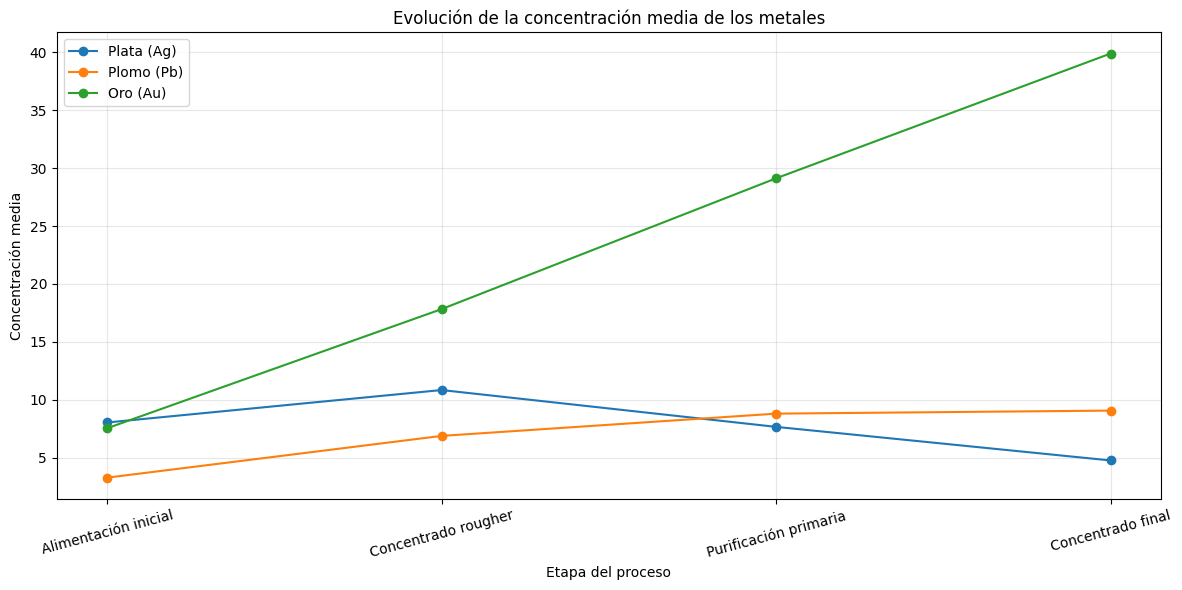

In [51]:
import matplotlib.pyplot as plt
# Definimos las etapas del proceso
etapas = [
    "Alimentación inicial",
    "Concentrado rougher",
    "Purificación primaria",
    "Concentrado final"
]

# Organizamos las concentraciones medias por metal
medias_ag = [
    medias_concentracion["rougher.input.feed_ag"],
    medias_concentracion["rougher.output.concentrate_ag"],
    medias_concentracion["primary_cleaner.output.concentrate_ag"],
    medias_concentracion["final.output.concentrate_ag"]
]

medias_pb = [
    medias_concentracion["rougher.input.feed_pb"],
    medias_concentracion["rougher.output.concentrate_pb"],
    medias_concentracion["primary_cleaner.output.concentrate_pb"],
    medias_concentracion["final.output.concentrate_pb"]
]

medias_au = [
    medias_concentracion["rougher.input.feed_au"],
    medias_concentracion["rougher.output.concentrate_au"],
    medias_concentracion["primary_cleaner.output.concentrate_au"],
    medias_concentracion["final.output.concentrate_au"]
]

# Construimos la gráfica
plt.figure(figsize=(12, 6))

plt.plot(
    etapas,
    medias_ag,
    marker="o",
    label="Plata (Ag)"
)

plt.plot(
    etapas,
    medias_pb,
    marker="o",
    label="Plomo (Pb)"
)

plt.plot(
    etapas,
    medias_au,
    marker="o",
    label="Oro (Au)"
)

# Personalizamos la visualización
plt.title("Evolución de la concentración media de los metales")
plt.xlabel("Etapa del proceso")
plt.ylabel("Concentración media")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

La visualización muestra que la concentración media de oro (`Au`) aumenta considerablemente durante todas las etapas del proceso, pasando de aproximadamente 7.55 unidades de concentración en la alimentación inicial a 39.89 en el concentrado final. Este comportamiento evidencia un enriquecimiento progresivo del producto en oro.

La concentración de plomo (`Pb`) también aumenta a lo largo del proceso, aunque de manera más moderada, desde 3.28 hasta 9.07 unidades de concentración.

Por otra parte, la plata (`Ag`) alcanza su mayor concentración media después de la flotación, con aproximadamente 10.85 unidades. Posteriormente, su concentración disminuye durante las etapas de purificación hasta alcanzar 4.77 unidades en el concentrado final.

En conjunto, los resultados indican que el proceso incrementa progresivamente la concentración de oro, mientras que la plata disminuye después de la flotación y el plomo aumenta de forma gradual.

Se compararán las distribuciones del tamaño de las partículas de alimentación entre los conjuntos de entrenamiento y prueba.

Esta comprobación es necesaria porque una diferencia considerable entre ambas distribuciones podría afectar la capacidad de generalización del modelo y producir una evaluación final poco representativa.

In [52]:
# Seleccionamos el tamaño de las partículas en la etapa rougher
tamano_particulas_entrenamiento = (
    oro_entrenamiento_limpio["rougher.input.feed_size"].ffill()
)

tamano_particulas_prueba = (
    oro_prueba["rougher.input.feed_size"].ffill()
)

# Revisamos sus estadísticas descriptivas
print("Entrenamiento:")
print(tamano_particulas_entrenamiento.describe())

print("\nPrueba:")
print(tamano_particulas_prueba.describe())

Entrenamiento:
count    14149.000000
mean        60.239856
std         23.005310
min          9.659576
25%         48.966751
50%         55.269784
75%         66.007526
max        484.967466
Name: rougher.input.feed_size, dtype: float64

Prueba:
count    5856.000000
mean       55.898866
std        22.707969
min         0.046369
25%        43.852884
50%        49.964796
75%        61.628003
max       477.445473
Name: rougher.input.feed_size, dtype: float64


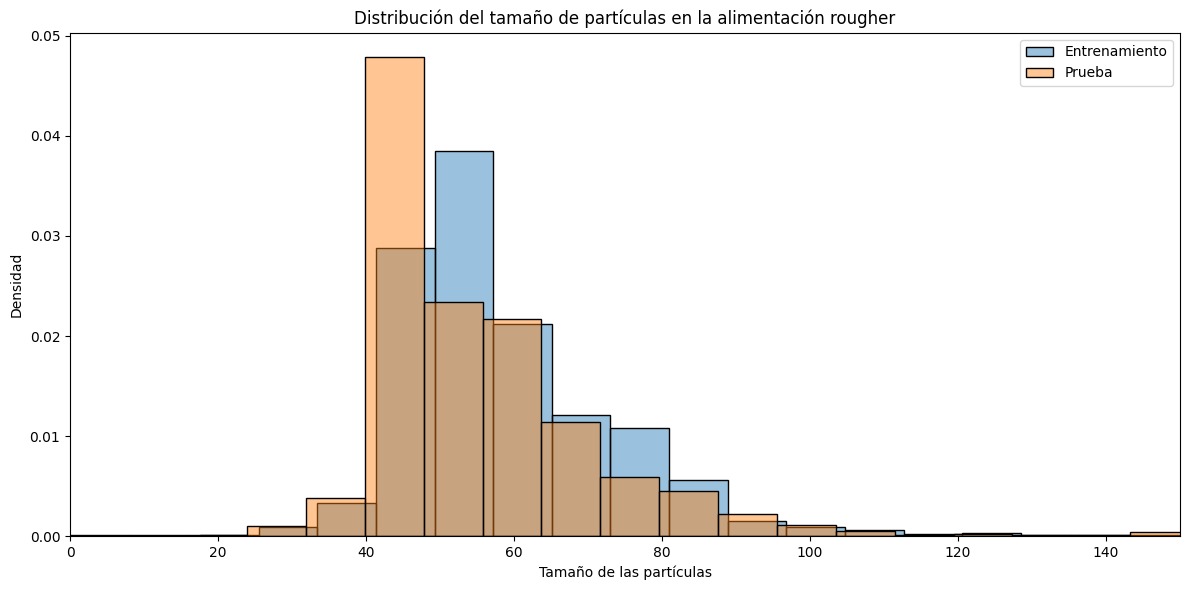

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    tamano_particulas_entrenamiento,
    bins=60,
    stat="density",
    alpha=0.45,
    label="Entrenamiento"
)

sns.histplot(
    tamano_particulas_prueba,
    bins=60,
    stat="density",
    alpha=0.45,
    label="Prueba"
)

plt.title(
    "Distribución del tamaño de partículas en la alimentación rougher"
)
plt.xlabel("Tamaño de las partículas")
plt.ylabel("Densidad")
plt.xlim(0, 150)
plt.legend()
plt.tight_layout()
plt.show()

Las distribuciones del tamaño de las partículas en los conjuntos de entrenamiento y prueba presentan una forma general similar y una dispersión prácticamente equivalente.

En entrenamiento, el tamaño medio de las partículas es de aproximadamente 60.24 unidades, mientras que en prueba es de 55.90. Las medianas son de 55.27 y 49.96 unidades, respectivamente, lo que muestra que la distribución de prueba está ligeramente desplazada hacia tamaños menores.

Ambas distribuciones concentran la mayor parte de sus observaciones aproximadamente entre 40 y 70 unidades y presentan una cola extendida hacia valores superiores. También se identifican valores extremos en ambos conjuntos.

A pesar de las diferencias moderadas en la media y la mediana, las distribuciones conservan formas y niveles de dispersión semejantes. Por lo tanto, no se observan diferencias suficientemente pronunciadas como para considerar que la evaluación posterior del modelo dejará de ser representativa.

### Concentración total en la alimentación inicial

Se calcula la concentración total de las sustancias presentes en la alimentación inicial mediante la suma de las concentraciones de plata (`Ag`), plomo (`Pb`), otros sólidos (`Sol`) y oro (`Au`).

Antes de realizar la suma, los valores ausentes se completan mediante relleno hacia adelante, teniendo en cuenta el orden cronológico de las observaciones.

In [54]:
# Seleccionamos las sustancias de la alimentación inicial
columnas_alimentacion = [
    "rougher.input.feed_ag",
    "rougher.input.feed_pb",
    "rougher.input.feed_sol",
    "rougher.input.feed_au"
]

# Creamos una copia para no modificar el dataset fuente
concentraciones_alimentacion = oro_fuente[
    columnas_alimentacion
].copy()

# Tratamos los valores ausentes
concentraciones_alimentacion = (
    concentraciones_alimentacion.ffill()
)

# Calculamos la concentración total por observación
concentracion_total_alimentacion = (
    concentraciones_alimentacion.sum(axis=1)
)

# Revisamos el resultado
print(concentracion_total_alimentacion.describe())

print(
    "\nValores ausentes:",
    concentracion_total_alimentacion.isna().sum()
)

count    22716.000000
mean        51.856810
std         17.934564
min          0.000000
25%         51.400302
50%         56.788595
75%         61.405688
max         76.978947
dtype: float64

Valores ausentes: 0


La media es menor que la mediana, lo cual puede estar relacionado con observaciones anormalmente bajas. El mínimo de 0.00 confirma que existen registros cuya concentración total es nula, pero todavía no eliminaremos esas observaciones. Primero calcularemos las concentraciones totales de las otras etapas y luego analizaremos conjuntamente las anomalías.


Se calcula la concentración total de plata (`Ag`), plomo (`Pb`), otros sólidos (`Sol`) y oro (`Au`) después de la etapa de flotación.

Este resultado permitirá comparar la concentración total del material antes y después del proceso rougher, además de identificar posibles observaciones anómalas.

In [55]:
# Seleccionamos las sustancias del concentrado rougher
columnas_concentrado_rougher = [
    "rougher.output.concentrate_ag",
    "rougher.output.concentrate_pb",
    "rougher.output.concentrate_sol",
    "rougher.output.concentrate_au"
]

# Creamos una copia para conservar intacto el dataset fuente
concentraciones_rougher = oro_fuente[
    columnas_concentrado_rougher
].copy()

# Tratamos los valores ausentes
concentraciones_rougher = concentraciones_rougher.ffill()

# Calculamos la concentración total por observación
concentracion_total_rougher = (
    concentraciones_rougher.sum(axis=1)
)

# Revisamos la distribución y los valores ausentes
print(concentracion_total_rougher.describe())

print(
    "\nValores ausentes:",
    concentracion_total_rougher.isna().sum()
)

count    22716.000000
mean        61.518427
std         23.412615
min          0.000000
25%         63.325353
50%         69.414309
75%         74.025452
max         90.964431
dtype: float64

Valores ausentes: 0


En comparación con la alimentación inicial, la concentración total media aumenta de 51.86 a 61.52. Sin embargo, tanto la media como la mediana están separadas considerablemente, y el mínimo sigue siendo 0, lo que refuerza la presencia de observaciones anormalmente bajas.

### Concentración total en el concentrado final

Se calcula la concentración total de plata (`Ag`), plomo (`Pb`), otros sólidos (`Sol`) y oro (`Au`) en el concentrado final obtenido después de completar las etapas de purificación.

Este cálculo permitirá comparar la concentración total del producto final con las etapas anteriores e identificar posibles observaciones anómalas.

In [56]:
# Seleccionamos las sustancias presentes en el concentrado final
columnas_concentrado_final = [
    "final.output.concentrate_ag",
    "final.output.concentrate_pb",
    "final.output.concentrate_sol",
    "final.output.concentrate_au"
]

# Creamos una copia para conservar intacto el dataset fuente
concentraciones_finales = oro_fuente[
    columnas_concentrado_final
].copy()

# Tratamos los valores ausentes
concentraciones_finales = concentraciones_finales.ffill()

# Calculamos la concentración total por observación
concentracion_total_final = (
    concentraciones_finales.sum(axis=1)
)

# Revisamos la distribución y los valores ausentes
print(concentracion_total_final.describe())

print(
    "\nValores ausentes:",
    concentracion_total_final.isna().sum()
)

count    22716.000000
mean        62.268599
std         20.860792
min          0.000000
25%         67.023260
50%         69.239194
75%         71.135495
max         80.210644
dtype: float64

Valores ausentes: 0


El mínimo de 0.00 confirma nuevamente la existencia de observaciones potencialmente anómalas. Además, la media es considerablemente menor que la mediana, posiblemente porque los valores nulos o cercanos a cero desplazan la media hacia abajo.

La concentración total aumenta después de la alimentación inicial. Sin embargo, la mediana del concentrado rougher y la del concentrado final son muy parecidas. Antes de establecer conclusiones definitivas, debemos observar las distribuciones completas.

Distribución de las concentraciones totales
Se comparan las distribuciones de las concentraciones totales en la alimentación inicial, el concentrado rougher y el concentrado final.

La visualización permitirá identificar acumulaciones de observaciones en valores iguales o cercanos a cero, así como comparar el comportamiento general de las tres etapas.

       Alimentación inicial  Concentrado rougher  Concentrado final
count          22716.000000         22716.000000       22716.000000
mean              51.856810            61.518427          62.268599
std               17.934564            23.412615          20.860792
min                0.000000             0.000000           0.000000
25%               51.400302            63.325353          67.023260
50%               56.788595            69.414309          69.239194
75%               61.405688            74.025452          71.135495
max               76.978947            90.964431          80.210644


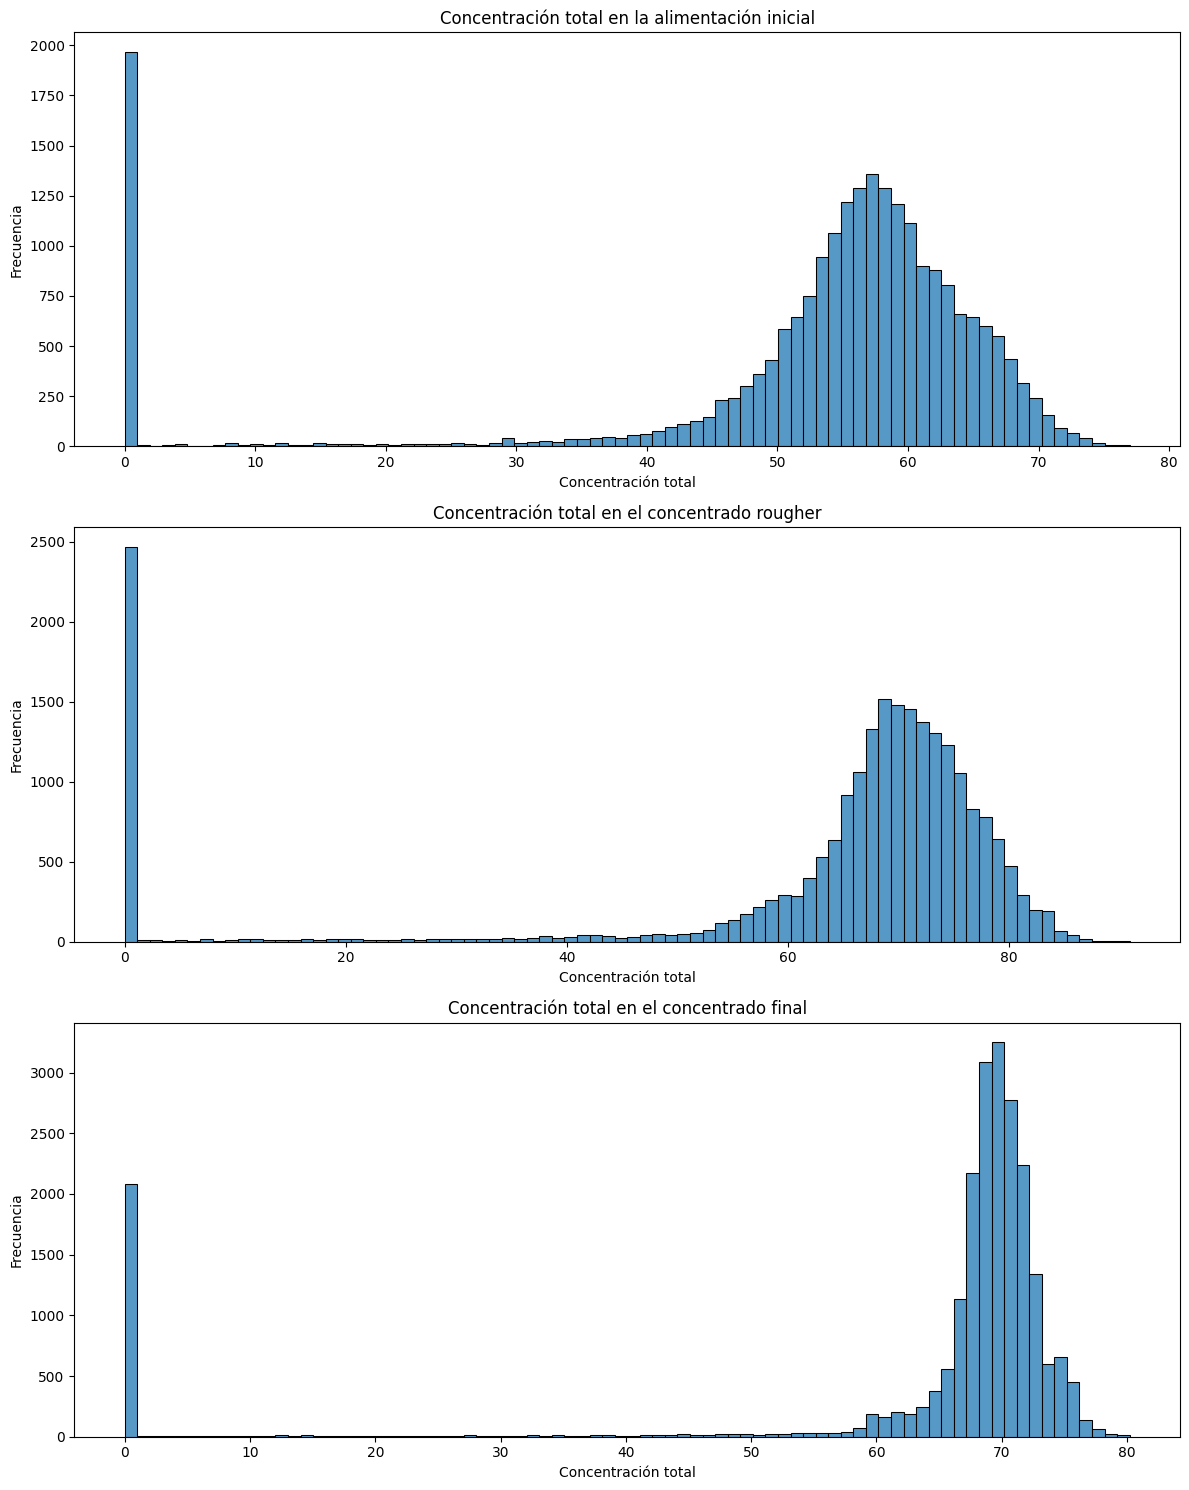

In [57]:
concentraciones_totales = pd.DataFrame(
    {
        "Alimentación inicial": concentracion_total_alimentacion,
        "Concentrado rougher": concentracion_total_rougher,
        "Concentrado final": concentracion_total_final
    }
)

print(concentraciones_totales.describe())



fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 15)
)

sns.histplot(
    data=concentraciones_totales,
    x="Alimentación inicial",
    bins=80,
    ax=axes[0]
)

axes[0].set_title(
    "Concentración total en la alimentación inicial"
)
axes[0].set_xlabel("Concentración total")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    data=concentraciones_totales,
    x="Concentrado rougher",
    bins=80,
    ax=axes[1]
)

axes[1].set_title(
    "Concentración total en el concentrado rougher"
)
axes[1].set_xlabel("Concentración total")
axes[1].set_ylabel("Frecuencia")

sns.histplot(
    data=concentraciones_totales,
    x="Concentrado final",
    bins=80,
    ax=axes[2]
)

axes[2].set_title(
    "Concentración total en el concentrado final"
)
axes[2].set_xlabel("Concentración total")
axes[2].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### Análisis de las distribuciones de concentración total

Las distribuciones muestran el comportamiento de la concentración total de plata (`Ag`), plomo (`Pb`), otros sólidos (`Sol`) y oro (`Au`) en tres etapas del proceso: alimentación inicial, concentrado rougher y concentrado final.

En las tres etapas se observa una distribución principal concentrada en valores considerablemente superiores a cero. Sin embargo, también aparece una acumulación independiente de observaciones alrededor de cero, claramente separada del comportamiento predominante de los datos.

En la alimentación inicial, la mayor parte de las concentraciones totales se encuentra aproximadamente entre 45 y 70 unidades, con una concentración central cercana a 57 unidades. En el concentrado rougher, la distribución principal se desplaza hacia valores mayores y se concentra principalmente entre 60 y 80 unidades. Finalmente, en el concentrado final, las observaciones se agrupan con mayor intensidad alrededor de 70 unidades.

Los picos observados alrededor de cero pueden representar mediciones anómalas, períodos de inactividad o registros que no describen adecuadamente el funcionamiento normal del proceso industrial. Estas observaciones también explican parcialmente que las medias de concentración sean inferiores a las medianas en las tres etapas.

Antes de eliminar estos registros, se cuantificará la cantidad y el porcentaje de observaciones con concentraciones iguales o cercanas a cero. Esto permitirá establecer un criterio de filtrado respaldado por la distribución observada.

### Cuantificación de concentraciones anómalas

Las distribuciones muestran grupos de observaciones con concentraciones totales iguales o cercanas a cero. Para determinar su magnitud, se contabilizan los valores exactamente iguales a cero y los valores inferiores o iguales a una unidad de concentración.

También se calcula el porcentaje que representan estas observaciones dentro del dataset. Los resultados permitirán establecer un criterio de filtrado respaldado por la distribución real de los datos.

In [58]:
# Contamos los valores exactamente iguales a cero
valores_iguales_cero = (
    concentraciones_totales == 0
).sum()

# Contamos los valores menores o iguales a 1
valores_cercanos_cero = (
    concentraciones_totales <= 1
).sum()

# Calculamos el porcentaje de valores menores o iguales a 1
porcentaje_cercanos_cero = (
    valores_cercanos_cero
    / len(concentraciones_totales)
    * 100
)

# Organizamos los resultados en un DataFrame
resumen_anomalias = pd.DataFrame(
    {
        "valores_iguales_a_cero": valores_iguales_cero,
        "valores_menores_o_iguales_a_1": valores_cercanos_cero,
        "porcentaje_menor_o_igual_a_1": porcentaje_cercanos_cero
    }
)

print(resumen_anomalias)

                      valores_iguales_a_cero  valores_menores_o_iguales_a_1  \
Alimentación inicial                    1584                           1966   
Concentrado rougher                     2009                           2464   
Concentrado final                       1671                           2082   

                      porcentaje_menor_o_igual_a_1  
Alimentación inicial                      8.654693  
Concentrado rougher                      10.846980  
Concentrado final                         9.165346  


El análisis confirmó una acumulación relevante de concentraciones totales iguales o cercanas a cero en las tres etapas del proceso.

En la alimentación inicial se identificaron 1.966 observaciones con concentraciones menores o iguales a una unidad, equivalentes al 8.65% del dataset. En el concentrado rougher se encontraron 2.464 observaciones, correspondientes al 10.85%, mientras que en el concentrado final se registraron 2.082 observaciones, equivalentes al 9.17%.

El concentrado rougher presenta la mayor proporción de registros anómalos. Estos valores se encuentran claramente separados de las distribuciones principales y pueden representar mediciones inválidas, períodos de inactividad o condiciones atípicas del proceso.


In [59]:
# Identificamos las observaciones anómalas en al menos una etapa
mascara_anomalias = (
    concentraciones_totales <= 1
).any(axis=1)

# Contamos las filas únicas afectadas
cantidad_anomalias = mascara_anomalias.sum()

# Calculamos el porcentaje sobre el dataset completo
porcentaje_anomalias = (
    cantidad_anomalias
    / len(concentraciones_totales)
    * 100
)

print("Observaciones únicas con anomalías:", cantidad_anomalias)
print(
    "Porcentaje de observaciones anómalas:",
    round(porcentaje_anomalias, 2),
    "%"
)

Observaciones únicas con anomalías: 2814
Porcentaje de observaciones anómalas: 12.39 %


Se identificaron 2.814 observaciones únicas con una concentración total menor o igual a una unidad en al menos una de las tres etapas analizadas. Estos registros representan aproximadamente el 12.39% del dataset fuente.

In [60]:
# Recuperamos las fechas de las observaciones anómalas
fechas_anomalas = oro_fuente.loc[
    mascara_anomalias,
    "date"
]

# Construimos una máscara para el conjunto de entrenamiento
mascara_entrenamiento_valido = (
    ~oro_entrenamiento_limpio["date"].isin(
        fechas_anomalas
    )
).to_numpy()

# Aplicamos el filtro de forma coordinada
caracteristicas_oro = caracteristicas_oro.iloc[
    mascara_entrenamiento_valido
].copy()

objetivo_oro_1 = objetivo_oro_1.iloc[
    mascara_entrenamiento_valido
].copy()

objetivo_oro_2 = objetivo_oro_2.iloc[
    mascara_entrenamiento_valido
].copy()

# Construimos una máscara para el conjunto de prueba
mascara_prueba_valida = (
    ~objetivos_prueba["date"].isin(
        fechas_anomalas
    )
).to_numpy()

# Aplicamos el mismo filtro a las características y objetivos de prueba
caracteristicas_prueba = caracteristicas_prueba.iloc[
    mascara_prueba_valida
].copy()

objetivos_prueba = objetivos_prueba.iloc[
    mascara_prueba_valida
].copy()

# Restablecemos los índices
caracteristicas_oro.reset_index(
    drop=True,
    inplace=True
)

objetivo_oro_1.reset_index(
    drop=True,
    inplace=True
)

objetivo_oro_2.reset_index(
    drop=True,
    inplace=True
)

caracteristicas_prueba.reset_index(
    drop=True,
    inplace=True
)

objetivos_prueba.reset_index(
    drop=True,
    inplace=True
)

In [61]:
print("Dimensiones después de eliminar anomalías")

print("\nCaracterísticas de entrenamiento:")
print(caracteristicas_oro.shape)

print("\nObjetivo rougher:")
print(objetivo_oro_1.shape)

print("\nObjetivo final:")
print(objetivo_oro_2.shape)

print("\nCaracterísticas de prueba:")
print(caracteristicas_prueba.shape)

print("\nObjetivos de prueba:")
print(objetivos_prueba.shape)

print("\nValores ausentes en entrenamiento:")
print(caracteristicas_oro.isna().sum().sum())

print("\nValores ausentes en prueba:")
print(caracteristicas_prueba.isna().sum().sum())

Dimensiones después de eliminar anomalías

Características de entrenamiento:
(13789, 52)

Objetivo rougher:
(13789,)

Objetivo final:
(13789,)

Características de prueba:
(5154, 52)

Objetivos de prueba:
(5154, 3)

Valores ausentes en entrenamiento:
0

Valores ausentes en prueba:
0


### Resultado del tratamiento de anomalías

Después de eliminar coordinadamente las observaciones con concentraciones totales anómalas, el conjunto de entrenamiento quedó conformado por 13.789 observaciones y 52 características. Los dos objetivos de entrenamiento conservaron la misma cantidad de registros.

El conjunto de prueba quedó compuesto por 5.154 observaciones y las mismas 52 características predictoras. Los objetivos reales de prueba también conservaron 5.154 registros, manteniendo la correspondencia entre las características y sus respectivos resultados.

Asimismo, se confirmó que las características de entrenamiento no contienen valores ausentes. Antes de continuar con el modelado, se realizará una última validación de los objetivos y las características de prueba.

### Validación final de los datos procesados

Se comprueba que las características y los objetivos de entrenamiento y prueba no contengan valores ausentes. También se verifica que las cantidades de observaciones y los índices permanezcan correctamente alineados después de eliminar las anomalías.

In [62]:
print("Valores ausentes en las características de entrenamiento:")
print(caracteristicas_oro.isna().sum().sum())

print("\nValores ausentes en el objetivo rougher:")
print(objetivo_oro_1.isna().sum())

print("\nValores ausentes en el objetivo final:")
print(objetivo_oro_2.isna().sum())

print("\nValores ausentes en las características de prueba:")
print(caracteristicas_prueba.isna().sum().sum())

print("\nValores ausentes en los objetivos de prueba:")
print(
    objetivos_prueba[
        [
            "rougher.output.recovery",
            "final.output.recovery"
        ]
    ].isna().sum()
)

print("\n¿Características y objetivos de entrenamiento están alineados?")
print(
    caracteristicas_oro.index.equals(objetivo_oro_1.index)
    and caracteristicas_oro.index.equals(objetivo_oro_2.index)
)

print("\n¿Características y objetivos de prueba tienen igual longitud?")
print(
    len(caracteristicas_prueba) == len(objetivos_prueba)
)

Valores ausentes en las características de entrenamiento:
0

Valores ausentes en el objetivo rougher:
0

Valores ausentes en el objetivo final:
0

Valores ausentes en las características de prueba:
0

Valores ausentes en los objetivos de prueba:
rougher.output.recovery    0
final.output.recovery      0
dtype: int64

¿Características y objetivos de entrenamiento están alineados?
True

¿Características y objetivos de prueba tienen igual longitud?
True


Después de eliminar las observaciones con concentraciones totales anómalas, se verificó la integridad de los conjuntos procesados.

Las características y los dos objetivos de entrenamiento no presentan valores ausentes y conservan índices correctamente alineados. Asimismo, las características y los objetivos reales de prueba tienen la misma cantidad de observaciones y se encuentran completamente disponibles.

Por lo tanto, los conjuntos están preparados para iniciar la construcción y evaluación de los modelos de Machine Learning.

## 3. Construcción y evaluación de modelos

### 3.1 Implementación de la métrica sMAPE

El desempeño de los modelos se evaluará mediante el error porcentual absoluto medio simétrico, conocido como `sMAPE`.

Esta métrica calcula la diferencia relativa entre los valores reales y las predicciones, considerando la magnitud de ambos valores. Posteriormente, se combinarán los resultados de la recuperación rougher y la recuperación final mediante la ponderación establecida para el proyecto.

In [63]:
import numpy as np
def calcular_smape(valores_reales, predicciones):
    numerador = np.abs(valores_reales - predicciones)

    denominador = (
        np.abs(valores_reales)
        + np.abs(predicciones)
    ) / 2

    errores = np.divide(
        numerador,
        denominador,
        out=np.zeros_like(
            numerador,
            dtype=float
        ),
        where=denominador != 0
    )

    return errores.mean() * 100


In [64]:
# Caso 1: predicciones idénticas a los valores reales
valores_reales_prueba = np.array([
    80.0,
    70.0,
    90.0
])

predicciones_exactas = np.array([
    80.0,
    70.0,
    90.0
])

smape_exacto = calcular_smape(
    valores_reales_prueba,
    predicciones_exactas
)

print(
    "sMAPE con predicciones exactas:",
    smape_exacto
)


# Caso 2: predicciones diferentes de los valores reales
predicciones_diferentes = np.array([
    75.0,
    65.0,
    85.0
])

smape_diferente = calcular_smape(
    valores_reales_prueba,
    predicciones_diferentes
)

print(
    "sMAPE con predicciones diferentes:",
    smape_diferente
)

sMAPE con predicciones exactas: 0.0
sMAPE con predicciones diferentes: 6.524435341639642


La función `calcular_smape()` fue validada mediante dos casos controlados.

Cuando las predicciones coincidieron exactamente con los valores reales, el sMAPE obtenido fue del 0%, lo que representa una predicción perfecta. Al introducir diferencias entre los valores reales y predichos, la métrica aumentó hasta aproximadamente 6.52%.

Estos resultados confirman que la función responde correctamente ante diferentes niveles de error y puede utilizarse para evaluar los modelos.

### Implementación del sMAPE final ponderado

La evaluación final combina el error de las predicciones de recuperación rougher y recuperación final.

El sMAPE de la etapa rougher recibe un peso del 25%, mientras que el sMAPE correspondiente a la recuperación final recibe un peso del 75%.

In [65]:
def calcular_smape_final(valores_reales, predicciones):
    # Convertimos ambos objetos en arreglos NumPy
    valores_reales = np.asarray(valores_reales)
    predicciones = np.asarray(predicciones)

    # Calculamos el sMAPE del objetivo rougher
    smape_rougher = calcular_smape(
        valores_reales[:, 0],
        predicciones[:, 0]
    )

    # Calculamos el sMAPE del objetivo final
    smape_recuperacion_final = calcular_smape(
        valores_reales[:, 1],
        predicciones[:, 1]
    )

    # Aplicamos las ponderaciones del proyecto
    smape_ponderado = (
        0.25 * smape_rougher
        + 0.75 * smape_recuperacion_final
    )

    return smape_ponderado

### Verificación del sMAPE final ponderado

Se verifica el funcionamiento de `calcular_smape_final()` mediante un ejemplo controlado con dos variables objetivo.

La primera columna representa la recuperación rougher y la segunda corresponde a la recuperación final. Primero se evalúan predicciones exactas y después predicciones con diferencias respecto a los valores reales.

In [66]:
# Definimos valores reales para ambos objetivos
valores_reales_dos_objetivos = np.array(
    [
        [80.0, 70.0],
        [85.0, 75.0],
        [90.0, 80.0]
    ]
)

# Caso 1: predicciones exactas
predicciones_exactas_dos_objetivos = np.array(
    [
        [80.0, 70.0],
        [85.0, 75.0],
        [90.0, 80.0]
    ]
)

smape_final_exacto = calcular_smape_final(
    valores_reales_dos_objetivos,
    predicciones_exactas_dos_objetivos
)

print(
    "sMAPE final con predicciones exactas:",
    smape_final_exacto
)


# Caso 2: predicciones diferentes
predicciones_diferentes_dos_objetivos = np.array(
    [
        [75.0, 65.0],
        [80.0, 70.0],
        [85.0, 75.0]
    ]
)

smape_final_diferente = calcular_smape_final(
    valores_reales_dos_objetivos,
    predicciones_diferentes_dos_objetivos
)

print(
    "sMAPE final con predicciones diferentes:",
    smape_final_diferente
)

sMAPE final con predicciones exactas: 0.0
sMAPE final con predicciones diferentes: 6.707768398535917


### Resultado de la validación del sMAPE final

La función `calcular_smape_final()` fue validada mediante dos casos controlados con las variables objetivo de recuperación rougher y recuperación final.

Cuando las predicciones coincidieron exactamente con los valores reales, el sMAPE final fue del 0%, confirmando que la función reconoce correctamente una predicción perfecta.

Al introducir diferencias entre los valores reales y predichos, el sMAPE final aumentó hasta aproximadamente 6.71%. Este resultado confirma que la función combina correctamente los errores de ambos objetivos y aplica las ponderaciones establecidas del 25% para la recuperación rougher y del 75% para la recuperación final.

### Preparación de las matrices de objetivos

Se combinan las variables `rougher.output.recovery` y `final.output.recovery` en una única matriz de objetivos de entrenamiento.

Asimismo, se seleccionan los dos objetivos reales del conjunto de prueba. De esta manera, cada observación queda asociada con los dos resultados que deberán ser predichos por los modelos.

In [67]:
# Combinamos los dos objetivos de entrenamiento
objetivos_entrenamiento = pd.concat(
    [
        objetivo_oro_1,
        objetivo_oro_2
    ],
    axis=1
)

# Asignamos nombres explícitos a las columnas
objetivos_entrenamiento.columns = [
    "rougher.output.recovery",
    "final.output.recovery"
]

# Seleccionamos únicamente los dos objetivos reales de prueba
objetivos_prueba_modelo = objetivos_prueba[
    [
        "rougher.output.recovery",
        "final.output.recovery"
    ]
].copy()

# Verificamos las dimensiones
print("Características de entrenamiento:")
print(caracteristicas_oro.shape)

print("\nObjetivos de entrenamiento:")
print(objetivos_entrenamiento.shape)

print("\nCaracterísticas de prueba:")
print(caracteristicas_prueba.shape)

print("\nObjetivos de prueba:")
print(objetivos_prueba_modelo.shape)

# Verificamos los valores ausentes
print("\nValores ausentes en los objetivos de entrenamiento:")
print(objetivos_entrenamiento.isna().sum())

print("\nValores ausentes en los objetivos de prueba:")
print(objetivos_prueba_modelo.isna().sum())

Características de entrenamiento:
(13789, 52)

Objetivos de entrenamiento:
(13789, 2)

Características de prueba:
(5154, 52)

Objetivos de prueba:
(5154, 2)

Valores ausentes en los objetivos de entrenamiento:
rougher.output.recovery    0
final.output.recovery      0
dtype: int64

Valores ausentes en los objetivos de prueba:
rougher.output.recovery    0
final.output.recovery      0
dtype: int64


La matriz de entrenamiento quedó conformada por 13.789 observaciones, 52 características predictoras y dos variables objetivo. Por su parte, el conjunto de prueba contiene 5.154 observaciones, las mismas 52 características y sus dos objetivos reales.

La función personalizada de sMAPE final se adapta al sistema de evaluación de Scikit-Learn mediante make_scorer().

Posteriormente, se configura una validación cruzada de cinco divisiones para evaluar los modelos sobre diferentes segmentos del conjunto de entrenamiento. La comparación se realizará utilizando el promedio del sMAPE final obtenido en las cinco evaluaciones.

In [68]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import KFold

# Convertimos la función personalizada en una métrica de Scikit-Learn
smape_scorer = make_scorer(
    calcular_smape_final,
    greater_is_better=False
)

# Configuramos la validación cruzada
validacion_cruzada = KFold(
    n_splits=5,
    shuffle=False
)

### Evaluación de la regresión lineal

Se construye un pipeline compuesto por un escalador estándar y un modelo de regresión lineal.

El escalado se realiza dentro del pipeline para que sus parámetros sean calculados exclusivamente con los datos de entrenamiento de cada división. El modelo se evalúa mediante validación cruzada de cinco bloques utilizando el sMAPE final como métrica.

In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [70]:
# Construimos el pipeline
modelo_lineal = Pipeline(
    steps=[
        (
            "escalado",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ]
)

# Evaluamos mediante validación cruzada
resultados_lineal = cross_val_score(
    modelo_lineal,
    caracteristicas_oro,
    objetivos_entrenamiento,
    scoring=smape_scorer,
    cv=validacion_cruzada
)

# Convertimos los errores negativos en valores positivos
smape_por_bloque_lineal = -resultados_lineal

# Calculamos el resultado promedio
smape_promedio_lineal = (
    smape_por_bloque_lineal.mean()
)

print("sMAPE por bloque:")
print(smape_por_bloque_lineal)

print(
    "\nsMAPE promedio de regresión lineal:",
    smape_promedio_lineal
)

sMAPE por bloque:
[12.11259129  8.73981597  8.42217781  8.06845471 12.71620639]

sMAPE promedio de regresión lineal: 10.011849233361328


### Resultado de la regresión lineal

La regresión lineal obtuvo valores de sMAPE final entre aproximadamente 8.07% y 12.72% durante la validación cruzada.

El sMAPE promedio fue de **10.01%**. Los bloques centrales presentaron los errores más bajos, mientras que el primer y el último bloque registraron resultados superiores. Esto indica que el rendimiento del modelo varía entre los diferentes segmentos temporales del conjunto de entrenamiento.

Este resultado se utilizará como referencia para comparar el desempeño de otros algoritmos y seleccionar el modelo con el menor sMAPE promedio.

### Evaluación del bosque aleatorio

Se evaluarán diferentes configuraciones de un modelo de bosque aleatorio, variando la profundidad máxima y la cantidad de árboles.

Cada combinación será evaluada mediante la misma validación cruzada de cinco bloques y la métrica sMAPE final. La configuración con el menor error promedio será seleccionada como la mejor versión del modelo.

In [71]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

In [72]:
mejor_smape_bosque = float("inf")
mejor_profundidad = None
mejor_numero_arboles = None

for profundidad in [3, 5, 7, 10]:
    for numero_arboles in [50, 100, 150]:

        modelo_bosque = RandomForestRegressor(
            n_estimators=numero_arboles,
            max_depth=profundidad,
            random_state=12345,
            n_jobs=-1
        )

        resultados_bosque = cross_val_score(
            modelo_bosque,
            caracteristicas_oro,
            objetivos_entrenamiento,
            scoring=smape_scorer,
            cv=validacion_cruzada,
            n_jobs=-1
        )

        smape_bosque = -resultados_bosque.mean()

        print(
            "Profundidad:",
            profundidad,
            "| Árboles:",
            numero_arboles,
            "| sMAPE:",
            round(smape_bosque, 4)
        )

        if smape_bosque < mejor_smape_bosque:
            mejor_smape_bosque = smape_bosque
            mejor_profundidad = profundidad
            mejor_numero_arboles = numero_arboles

print("\nMejor profundidad:", mejor_profundidad)
print("Mejor número de árboles:", mejor_numero_arboles)
print(
    "Mejor sMAPE del bosque aleatorio:",
    mejor_smape_bosque
)

Profundidad: 3 | Árboles: 50 | sMAPE: 8.8432
Profundidad: 3 | Árboles: 100 | sMAPE: 8.8067
Profundidad: 3 | Árboles: 150 | sMAPE: 8.7669
Profundidad: 5 | Árboles: 50 | sMAPE: 9.3244
Profundidad: 5 | Árboles: 100 | sMAPE: 9.2426
Profundidad: 5 | Árboles: 150 | sMAPE: 9.2021
Profundidad: 7 | Árboles: 50 | sMAPE: 9.5046
Profundidad: 7 | Árboles: 100 | sMAPE: 9.4236
Profundidad: 7 | Árboles: 150 | sMAPE: 9.3951
Profundidad: 10 | Árboles: 50 | sMAPE: 9.6684
Profundidad: 10 | Árboles: 100 | sMAPE: 9.5187
Profundidad: 10 | Árboles: 150 | sMAPE: 9.4995

Mejor profundidad: 3
Mejor número de árboles: 150
Mejor sMAPE del bosque aleatorio: 8.766937329721369


### Resultado del bosque aleatorio

Se evaluaron doce configuraciones del modelo de bosque aleatorio mediante validación cruzada, combinando diferentes profundidades máximas y cantidades de árboles.

La mejor configuración utilizó una profundidad máxima de 3 y 150 árboles, obteniendo un sMAPE promedio de aproximadamente **8.77%**.

Este resultado fue inferior al **10.01%** obtenido por la regresión lineal, por lo que el bosque aleatorio presentó el mejor desempeño durante la validación cruzada.

También se observó que el error aumentó al utilizar árboles más profundos. Esto indica que incrementar la complejidad del modelo no produjo una mejora en su capacidad de generalización.

Se comparan los valores medios de sMAPE obtenidos por la regresión lineal y el bosque aleatorio durante la validación cruzada.

El modelo con el menor sMAPE será seleccionado para el entrenamiento definitivo y la evaluación sobre el conjunto de prueba.

In [73]:
resultados_modelos = pd.DataFrame(
    {
        "modelo": [
            "Regresión lineal",
            "Bosque aleatorio"
        ],
        "smape_validacion": [
            smape_promedio_lineal,
            mejor_smape_bosque
        ]
    }
)

resultados_modelos = resultados_modelos.sort_values(
    by="smape_validacion"
).reset_index(drop=True)

print(resultados_modelos)

             modelo  smape_validacion
0  Bosque aleatorio          8.766937
1  Regresión lineal         10.011849


### Selección del mejor modelo

La comparación mediante validación cruzada mostró que el bosque aleatorio obtuvo el mejor desempeño, con un sMAPE promedio de aproximadamente **8.77%**, frente al **10.01%** alcanzado por la regresión lineal.

Esto representa una reducción aproximada de **1.24 puntos porcentuales** en el error de validación. En consecuencia, se seleccionará el bosque aleatorio con una profundidad máxima de 3 y 150 árboles para realizar la evaluación final sobre el conjunto de prueba.

In [74]:
# Construimos el modelo con los mejores hiperparámetros
mejor_modelo = RandomForestRegressor(
    n_estimators=mejor_numero_arboles,
    max_depth=mejor_profundidad,
    random_state=12345,
    n_jobs=-1
)

# Entrenamos el modelo
mejor_modelo.fit(
    caracteristicas_oro,
    objetivos_entrenamiento
)

# Generamos las predicciones sobre prueba
predicciones_prueba = mejor_modelo.predict(
    caracteristicas_prueba
)

# Calculamos el sMAPE final
smape_prueba = calcular_smape_final(
    objetivos_prueba_modelo.to_numpy(),
    predicciones_prueba
)

print(
    "sMAPE final del bosque aleatorio en prueba:",
    smape_prueba
)


sMAPE final del bosque aleatorio en prueba: 7.055180860206217


### Resultado final del bosque aleatorio

El bosque aleatorio seleccionado obtuvo un sMAPE final de aproximadamente **7.06%** sobre el conjunto de prueba.

Este resultado es inferior al sMAPE promedio de **8.77%** obtenido durante la validación cruzada, lo que indica que el modelo mantuvo un buen desempeño sobre las observaciones no utilizadas durante el entrenamiento.

La diferencia moderada entre ambos resultados no evidencia un deterioro en la capacidad de generalización del modelo. No obstante, antes de establecer una conclusión definitiva, su desempeño debe compararse con un modelo de referencia.

Se verifica que las predicciones tengan las dimensiones esperadas y que no contengan valores ausentes o infinitos antes de utilizarlas en la evaluación final.

In [75]:
print("Dimensiones de las predicciones:")
print(predicciones_prueba.shape)

print("\nValores ausentes en las predicciones:")
print(np.isnan(predicciones_prueba).sum())

print("\nValores infinitos en las predicciones:")
print(np.isinf(predicciones_prueba).sum())

Dimensiones de las predicciones:
(5154, 2)

Valores ausentes en las predicciones:
0

Valores infinitos en las predicciones:
0


### Evaluación mediante un modelo de referencia

Se construye un modelo de referencia que predice el valor promedio observado para cada variable objetivo.

El bosque aleatorio deberá obtener un sMAPE menor que este modelo básico para demostrar que aprende patrones útiles de las características predictoras.

In [76]:
from sklearn.dummy import DummyRegressor

modelo_referencia = DummyRegressor(
    strategy="mean"
)

modelo_referencia.fit(
    caracteristicas_oro,
    objetivos_entrenamiento
)

predicciones_referencia = modelo_referencia.predict(
    caracteristicas_prueba
)

smape_referencia = calcular_smape_final(
    objetivos_prueba_modelo.to_numpy(),
    predicciones_referencia
)

print(
    "sMAPE final del modelo de referencia:",
    smape_referencia
)

print(
    "sMAPE final del bosque aleatorio:",
    smape_prueba
)

sMAPE final del modelo de referencia: 7.7704787867339675
sMAPE final del bosque aleatorio: 7.055180860206217


### Comparación con el modelo de referencia
 El modelo de referencia, basado en la predicción del promedio de cada variable objetivo, obtuvo un sMAPE final de aproximadamente **7.77%**. Por su parte, el bosque aleatorio alcanzó un sMAPE final de **7.06%**, lo que representa una reducción aproximada de **0.72 puntos porcentuales** respecto al modelo de referencia. Este resultado confirma que el bosque aleatorio supera la estrategia de predicción constante y logra aprender relaciones útiles entre las características del proceso y las recuperaciones de oro. Aunque la diferencia es moderada, el modelo seleccionado demuestra una capacidad predictiva superior a la referencia básica.

Además del sMAPE ponderado, se calcula el error individual correspondiente a la recuperación rougher y la recuperación final.

In [77]:
# Calculamos el sMAPE de la recuperación rougher
smape_rougher_prueba = calcular_smape(
    objetivos_prueba_modelo[
        "rougher.output.recovery"
    ].to_numpy(),
    predicciones_prueba[:, 0]
)

# Calculamos el sMAPE de la recuperación final
smape_recuperacion_final_prueba = calcular_smape(
    objetivos_prueba_modelo[
        "final.output.recovery"
    ].to_numpy(),
    predicciones_prueba[:, 1]
)

# Mostramos los resultados
print(
    "sMAPE de la recuperación rougher:",
    smape_rougher_prueba
)

print(
    "sMAPE de la recuperación final:",
    smape_recuperacion_final_prueba
)

print(
    "sMAPE ponderado final:",
    smape_prueba
)

sMAPE de la recuperación rougher: 4.993679372691551
sMAPE de la recuperación final: 7.742348022711107
sMAPE ponderado final: 7.055180860206217


### Evaluación individual de las variables objetivo

El bosque aleatorio obtuvo un sMAPE de aproximadamente **4.99%** para la recuperación rougher y de **7.74%** para la recuperación final.

Estos resultados muestran que el modelo predice con mayor precisión la recuperación correspondiente a la etapa rougher. La recuperación final presenta un error superior, lo que indica una mayor dificultad para estimar el resultado después de completar todas las etapas de purificación.

Al aplicar las ponderaciones establecidas en el proyecto, 25% para la recuperación rougher y 75% para la recuperación final, se obtiene un sMAPE ponderado de aproximadamente **7.06%**.

La recuperación final ejerce una mayor influencia sobre la métrica global debido a su ponderación del 75%. Por esta razón, su mayor error explica que el resultado ponderado se encuentre más próximo al sMAPE de la recuperación final.


In [78]:
resultados_finales = pd.DataFrame(
    {
        "Métrica": [
            "sMAPE rougher",
            "sMAPE recuperación final",
            "sMAPE ponderado del bosque aleatorio",
            "sMAPE del modelo de referencia"
        ],
        "Resultado (%)": [
            smape_rougher_prueba,
            smape_recuperacion_final_prueba,
            smape_prueba,
            smape_referencia
        ]
    }
)

resultados_finales["Resultado (%)"] = (
    resultados_finales["Resultado (%)"].round(2)
)

print(resultados_finales)

                                Métrica  Resultado (%)
0                         sMAPE rougher           4.99
1              sMAPE recuperación final           7.74
2  sMAPE ponderado del bosque aleatorio           7.06
3        sMAPE del modelo de referencia           7.77



El bosque aleatorio obtuvo un sMAPE de **4.99%** para la recuperación rougher y de **7.74%** para la recuperación final.

Al aplicar las ponderaciones establecidas, 25% para la recuperación rougher y 75% para la recuperación final, el modelo alcanzó un sMAPE ponderado de **7.06%**.

Por su parte, el modelo de referencia obtuvo un sMAPE de **7.77%**. Por lo tanto, el bosque aleatorio redujo el error en aproximadamente **0.71 puntos porcentuales** y demostró una capacidad predictiva superior a la estrategia basada en predecir los valores promedio.

Aunque la mejora frente al modelo de referencia es moderada, los resultados confirman que el bosque aleatorio logra identificar relaciones útiles entre las características disponibles y la recuperación de oro.



El proyecto permitió desarrollar un modelo de Machine Learning para predecir la recuperación de oro durante las etapas rougher y final del proceso industrial.

Después de preparar los datos, analizar las concentraciones de metales, comparar la distribución del tamaño de las partículas y eliminar concentraciones anómalas, se evaluaron modelos de regresión lineal y bosque aleatorio mediante validación cruzada.

El bosque aleatorio obtuvo el mejor desempeño, con un sMAPE promedio de validación de **8.77%** y un sMAPE final de **7.06%** sobre el conjunto de prueba. Además, superó al modelo de referencia, cuyo sMAPE fue de **7.77%**.

Por lo tanto, el modelo seleccionado logra identificar patrones útiles en los datos y puede servir como herramienta de apoyo para estimar la recuperación de oro y optimizar el proceso productivo.